# Fig. 6c: model of sorting accuracy for Kilosort 4 (biophysical, spontaneous, Neuropixels)

**author**: laquitainesteeve@gmail.com

**purpose**: model the relationship between a ground truth neuron's sorting accuracy and its biological features (not available to experimentalists) with a fractional regression (binomial GLM with logit link). The panel shows the neurons' accuracy ranked by the model's predicted accuracy, the model's prediction and the cross-validated pseudo R-squared (McFadden). Source data and svg are saved in figures/8_source_data/fig6c/.

**method**
* ground truth: first 10 minutes of the biophysical spontaneous simulation (1,388 neurons within 50 microns of the contacts); sorting: Kilosort 4 (10 min)
* sorting accuracy of a ground truth neuron: its best agreement score (delta_time = 1.3 ms) with a sorted unit
* features: firing rate, synapse class, etype and layer (one-hot), distance to the nearest site, SNR and spatial extent of the ground truth waveforms, exc_mini_frequency, dynamics_holding_current (`model_template` is dropped: not enough repeats for cross-validation)
* features are z-scored; the model is regularized with an elastic net (alpha=0, L1_wt=1: lasso), 100 iterations, convergence tolerance 1e-10
* cross-validation: 100 random 75% train / 25% test splits; R-squared: McFadden pseudo R-squared, median over the splits whose fit succeeded (NaN otherwise). As in the paper's pipeline, the neurons without spikes (missing snr and spatial extent) are kept in the cross-validated dataset; the model fits ignore rows with a missing feature
* the figure shows the model fitted on the full dataset

In [1]:
%load_ext autoreload
%autoreload 2
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
import copy
import numpy as np
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import extract_waveforms
from spikeinterface import qualitymetrics as qm
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.metrics import metrics
from src.nodes.models.Fr import dataloader as fr_dataloader
from src.nodes.models.Fr.models import FrModel

# paths
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"
GT_PATH = "dataset/00_raw/ground_truth_npx_spont_10m"          # first 10 min
KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"

# parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 3
MS_AFTER = 3
DURATION_SEC = 600
DT = 1.3
MAX_SPIKES_PER_UNIT = 500
SEED = 0
JOB_KWARGS = dict(n_jobs=16, chunk_duration="1s", progress_bar=False)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the datasets

In [2]:
%%time

# recording (first 10 minutes, as for the sorting)
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property("location", Recording.get_property("location")[:, :2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))

# ground truth and sorting
SortingTrue = si.load_extractor(GT_PATH)
Sorting = si.load_extractor(KS4_PATH)
display(Recording)
display(SortingTrue)
display(Sorting)

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

NumpyFolderSorting: 1388 units - 1 segments - 40.0kHz

NumpyFolderSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 7.92 ms, sys: 0 ns, total: 7.92 ms
Wall time: 7.75 ms


## Ground truth waveforms (in memory; sparse, 6 ms window)

In [3]:
%%time

We = extract_waveforms(Recording, SortingTrue, folder=None, mode="memory", sparse=True, ms_before=MS_BEFORE, ms_after=MS_AFTER,
                       max_spikes_per_unit=MAX_SPIKES_PER_UNIT, seed=SEED, **JOB_KWARGS)
display(We)

WaveformExtractor: 384 channels - 1388 units - 1 segments
  before:120 after:120 n_per_units:500 - sparse

CPU times: user 8.11 s, sys: 14 s, total: 22.1 s
Wall time: 3min 31s


## Dataset: predictors (ground truth neuron features) and target (sorting accuracy)

In [4]:
%%time

dataset = pd.DataFrame()

# firing rate
n_spikes = SortingTrue.get_total_num_spikes()
dataset["firing_rate"] = [n_spikes[unit] / DURATION_SEC for unit in n_spikes]

# synapse class
dataset = fr_dataloader.set_synapse_class(dataset, SortingTrue)

# etype (one-hot)
dataset = pd.merge(dataset, pd.get_dummies(SortingTrue.get_property("etype")), left_index=True, right_index=True)

# layer (one-hot)
layers = np.array(["2/3" if (w == "2") or (w == "3") else w for w in SortingTrue.get_property("layer")])
layer_df = pd.get_dummies(layers)
layer_df.columns = ["layer_1", "layer_23", "layer_4", "layer_5", "layer_6"]
dataset = pd.merge(dataset, layer_df, left_index=True, right_index=True)

# 3D site coordinates (the recording's "location" property; get_probe().contact_positions has a null z for this recording)
Rec = si.load_extractor(RECORDING_PATH)
channel_coord = Rec.get_property("location")
channel_ids = Rec.get_channel_ids()

# distance to the nearest site (um)
unit_xyz = np.c_[SortingTrue.get_property("x"), SortingTrue.get_property("y"), SortingTrue.get_property("z")]
dataset["distance"] = [np.min(np.linalg.norm(channel_coord - xyz, axis=1)) for xyz in unit_xyz]

# signal-to-noise ratio
snrs = qm.compute_snrs(We, peak_sign="neg", peak_mode="extremum", unit_ids=We.sorting.unit_ids)
dataset["snr"] = snrs.values()

# spike spatial extent
max_chids = ttools.get_template_extremum_channel(We, peak_sign="neg")
dataset["spatial_extent"] = [
    metrics.get_spatial_spread(We, unit, max_chids, channel_ids, channel_coord)["spatial_spread"] for unit in We.unit_ids
]

# other features
dataset["exc_mini_frequency"] = SortingTrue.get_property("exc_mini_frequency")
dataset["dynamics_holding_current"] = SortingTrue.get_property("dynamics_holding_current")

# target: sorting accuracy
dataset["sorting_accuracy"] = fr_dataloader.get_accuracy(Sorting, SortingTrue, delta_time=DT).values
dataset.index = SortingTrue.unit_ids

# curate: drop units with an infinite feature. Units without spikes in the 10 minutes have no waveform: their snr and
# spatial_extent are missing. As in the paper's pipeline they stay in the dataset used for cross-validation (the model
# fits ignore rows with a missing feature), and are removed for the figure
dataset = dataset.drop(index=dataset.index[dataset.sum(axis=1) == np.inf])
predictors = dataset.columns.drop(["sorting_accuracy"])
print("neurons:", len(dataset), "| with a missing feature:", int(dataset.isna().any(axis=1).sum()), "| predictors:", len(predictors))

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


neurons: 1388 | with a missing feature: 78 | predictors: 21
CPU times: user 3.57 s, sys: 363 ms, total: 3.94 s
Wall time: 3.94 s


## Fractional regression model (cross-validated R-squared and fit on the full dataset)

In [5]:
%%time

# cross-validated pseudo R-squared (100 random 75% / 25% splits)
frmodel = FrModel(predictors, "sorting_accuracy", order=1)
flc_results = frmodel.evaluate(dataset=dataset, seeds=np.arange(0, 100, 1), scale_data=True, regularization="elastic_net",
                               maxiter=100, cnvrg_tol=1e-10)
print("model: ", frmodel.formula)
display(flc_results["metric_stats"])
r2_folds = np.array([m["r-squared"] for m in flc_results["metric_data"]], dtype=float)
print("folds with a finite R-squared:", int(np.isfinite(r2_folds).sum()), "of", len(r2_folds), "(the median is taken over these folds)")

model:  sorting_accuracy ~ 1  + firing_rate + synapse_class + bAC + bNAC + bSTUT + cACint + cADpyr + cNAC + cSTUT + dNAC + dSTUT + layer_1 + layer_23 + layer_4 + layer_5 + layer_6 + distance + snr + spatial_extent + exc_mini_frequency + dynamics_holding_current


{'r2_median': 0.40242072893375125,
 'r2_std': 0.037262740610505225,
 'r2_ci95': 0.008490142993825524}

folds with a finite R-squared: 74 of 100 (the median is taken over these folds)
CPU times: user 26 s, sys: 0 ns, total: 26 s
Wall time: 26 s


In [6]:
%%time

# fit on the full dataset
fullresults = frmodel.evaluate_on_full_dataset(dataset=dataset, scale_data=True, regularization="elastic_net",
                                               maxiter=100, cnvrg_tol=1e-10, verbose=False)
fullmodel = fullresults["metric_data"]["model"]
prediction = fullmodel.model.predict(fullmodel.params)

2026-10-31 22:31:23,512 - root - utils.py - evaluate_on_full_dataset - INFO - Z-scoring the dataset features...


2026-10-31 22:31:23,515 - root - utils.py - evaluate_on_full_dataset - INFO - Done Z-scoring.


2026-10-31 22:31:23,878 - root - utils.py - evaluate_on_full_dataset - INFO - Done training the model.


CPU times: user 371 ms, sys: 0 ns, total: 371 ms
Wall time: 371 ms


## Source data: neurons ranked by the model's predicted accuracy

In [7]:
# neurons sorted by predicted accuracy
dataset2 = dataset.dropna()     # neurons used by the fit (a missing feature is ignored by the model)
dataset2["prediction"] = prediction
df_sorted = dataset2.sort_values(by="prediction", ascending=False)

# source data
df = pd.DataFrame({
    "rank": np.arange(1, len(df_sorted) + 1),
    "unit_id": df_sorted.index.values,
    "sorting_accuracy": df_sorted["sorting_accuracy"].values,
    "prediction": df_sorted["prediction"].values,
})
df_r2 = pd.DataFrame({"r2_median": [float(flc_results["metric_stats"]["r2_median"])], "n_neurons": [len(df)],
                      "n_folds_finite": [int(np.isfinite(r2_folds).sum())]})
display(df.head()); display(df_r2)

,rank,unit_id,sorting_accuracy,prediction
0,1,2536998,0.986714,0.997834
1,2,1981516,0.997592,0.994741
2,3,3575179,0.961606,0.976377
3,4,3891529,0.432419,0.974759
4,5,2121825,0.942363,0.973419


,r2_median,n_neurons,n_folds_finite
0,0.402421,1310,74


In [8]:
def plot_source_data(df: pd.DataFrame, df_r2: pd.DataFrame):
    """Neurons' sorting accuracy (data) and the model's prediction, ranked by predicted accuracy"""

    fig, ax = plt.subplots(1, figsize=(3.3, 1.2))
    ax.plot(df["sorting_accuracy"].values, "o", color="w", markeredgecolor=(0.5, 0.5, 0.5), markeredgewidth=0.5, markersize=2, label="Data")
    ax.plot(df["prediction"].values, "-", color=(0.93, 0.13, 0.15), linewidth=1.8, label="Regression model")

    # cross-validated R-squared
    ax.annotate(text=f"$R^2=${df_r2['r2_median'].iloc[0]:.2f}", xy=(0.78 * len(df), 0.45), color="k", fontsize=7)

    # legend (data: open grey circle; model: red bar)
    handles = [Line2D([], [], marker="o", linestyle="", color="w", markeredgecolor=(0.5, 0.5, 0.5), markeredgewidth=0.5, markersize=2.5),
               Line2D([], [], color=(0.93, 0.13, 0.15), linewidth=3.5)]
    ax.legend(handles, ["Data", "Regression model"], bbox_to_anchor=(0.62, 1.05), loc="upper left", handlelength=1.6, **legend_cfg)

    # aesthetics
    ax.set_title("Model of sorting accuracy for ks4 (Biophy. Spont, NPX)", fontweight="bold", fontsize=6.5)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.set_ylabel("Sorting accuracy (ratio)")
    ax.set_yticks([0, 0.5, 1.0])

    # disconnect axes (R style)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 182 ms, sys: 0 ns, total: 182 ms
Wall time: 182 ms


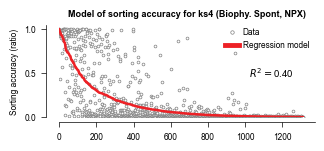

In [9]:
%%time

# plot
fig, ax = plot_source_data(df, df_r2)

# save figure
os.makedirs("figures/8_source_data/fig6c", exist_ok=True)
plt.savefig("figures/8_source_data/fig6c/fig6c.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6c/fig6c.xlsx", index=False)
df_r2.to_excel("figures/8_source_data/fig6c/fig6c_r2.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 36.5 ms, sys: 0 ns, total: 36.5 ms
Wall time: 36.4 ms


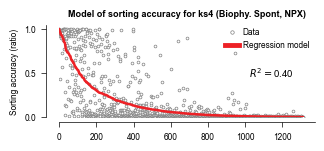

In [10]:
%%time

df = pd.read_excel("figures/8_source_data/fig6c/fig6c.xlsx")
df_r2 = pd.read_excel("figures/8_source_data/fig6c/fig6c_r2.xlsx")
fig, ax = plot_source_data(df, df_r2)